In [115]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Figure 3 builder — Explain mode, ERA5

Everything that draws lives in `figure3_builder.py`; this notebook only *selects*.

- **Version A** — rows are targets, columns are `[error] [attribution] [ranking]`, the
  ranking drawn vertically with tilted feature labels.
- **Version split** — all maps on one row, the rankings on the next; each ranking spans
  its own target's pair of maps.

The configuration cell below holds the selection knobs and their defaults. Layout,
geometry and typography knobs are documented in `figure3_builder.py` and can be changed
the same way, through `f3.configure(...)` — `f3.CONFIG_KEYS` lists every accepted name.

Attributions are memoised on the full selection (dataset · model · prediction time ·
node · method), so re-rendering a figure or switching layout is instant; only a new
target, node or timestep costs an IG run (~30 s each).

In [116]:
%config InlineBackend.figure_formats = ['retina']
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# `figure3_builder.py` sits next to this notebook — importable whether the kernel
# was started in notebooks/ or in the repo root.
for _p in (Path.cwd(), Path.cwd() / "notebooks"):
    if (_p / "figure3_builder.py").exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
        break

import matplotlib.pyplot as plt
import figure3_builder as f3

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Configuration

Everything selected here; re-run a build cell after changing it.

In [117]:
f3.configure(
    # ── data / model / target ────────────────────────────────────────────────
    DATASET     = "aug2020.zarr",            # under backend/data/era5_datasets/
    PRED_TIME   = "2020-08-27T12:00:00",     # timestep to predict
    MODEL       = "graphcast",               # key into inf.PRESET_MODELS
    NODE_LATLON = (31.5, -93.0),             # target node (nearest grid cell is used)

    # ── attribution ──────────────────────────────────────────────────────────
    METHOD     = "ig",       # "ig" (paper figure, ~30 s per target) | "ixg" (~1 s, same story)
    IG_STEPS   = 16,
    INPUT_STEP = "t-6h",     # "t-6h" | "t-12h" — the input timestep the attribution maps show
    ATTR_SCALE = "max",      # "max" = UI semantics | "pct" = clip the top tail so two
    ATTR_PCT   = 99.0,       #   panels are comparable in shape (see attr_vmax docstring)

    # ── what each row shows ──────────────────────────────────────────────────
    # (variable, level); level is None for surface fields. An optional
    # node=(lat, lon) overrides NODE_LATLON for that row alone.
    ROWS = [
        dict(target=("temperature", 925),              source=("temperature", 925)),
        dict(target=("total_precipitation_6hr", None), source=("total_precipitation_6hr", None)),
    ],

    # ── map crop ─────────────────────────────────────────────────────────────
    CROP_CENTER = None,      # (lat, lon) every crop is centred on; None = each row's own node
    CROP_HEIGHT = 26.0,      # degrees of latitude at ZOOM = 1
    ZOOM        = 0.8,       # crop height = CROP_HEIGHT / ZOOM
    CROP_ASPECT = 1.8,       # longitude span of a crop, as a multiple of CROP_HEIGHT. Also the
                             #   reference map aspect in make_figure / make_figure_vrank when the
                             #   panel size is not pinned below. The split layout ignores it —
                             #   there the panel's own shape sets the longitude span

    # ── panels ───────────────────────────────────────────────────────────────
    ERROR_SCALE     = "crop",   # "shared" (one max across rows, UI semantics) | "crop" | "global"
    SHOW_TOP_SOURCE = False,    # make_figure / make_figure_vrank: add a 4th column with the
                                #   top-ranked source's map. The split layout has no such column
    RANK_TOP_N      = 10,       # ranking rows — honoured by every layout; f3.SPLIT_OVERRIDES
                                #   only raises it to 10 when it is not named here
    RANK_TICK_ROT   = 90,       # tilt of the feature labels, in degrees — vertical rankings only
                                #   (versions A and split; the sidebar's labels are always
                                #   upright). SPLIT_OVERRIDES pins 90 unless named here, as it is
    RANK_XMAX=22,

    # ── panel sizing, in inches — make_figure only ───────────────────────────
    # None = derive as before, from FIG_WIDTH / WIDTH_RATIOS / CROP_ASPECT. Pin either
    # width and the figure sizes itself around the columns instead; columns left at None
    # keep their WIDTH_RATIOS share of FIG_WIDTH.
    MAP_W = 1.7,            # width of one map panel (every column but the last)
    RANK_W = 1,           # width of the ranking's BAR AREA; its label gutter is added on top
    ROW_H = 1,            # height of a row's panels, maps and ranking alike. Overrides the
                             #   RANK_TOP_N * RANK_ROW_PITCH floor — it warns instead of growing
)


[inference] Using global TOA normalization from toa_solar_radiation_max.pt
model graphcast_scripted.pt · aug2020.zarr · 1429 coastline parts


# Paper version

In [124]:
f3.configure(PANEL_LETTERS=True, 
             PANEL_LETTER_SCOPE="all", 
             PANEL_LETTER_FMT="({})", 
             PANEL_LETTER_START="a",
             PANEL_LETTER_PAD=(-3, 0))  # nudge the letters left to clear the y-axis title

f3.configure(LEGEND_FS=6.5,CHIP_FS=6.5)
f3.configure(V2_RANK_HORIZ=True)  # split layout: horizontal ranking, vertical maps
f3.configure(RANK_XMAX=18)
f3.configure(CB_H=0.03)
f3.configure(SAVE_TIGHT=True)

saved figure3_paper_final_temp925-precip_20200827T1200_31.5N93.0W.pdf + .png — canvas 5.65 x 2.41 in, file 5.34 x 2.01 in


PosixPath('/workspace/gnn-view/notebooks/figure3_paper_final_temp925-precip_20200827T1200_31.5N93.0W.pdf')

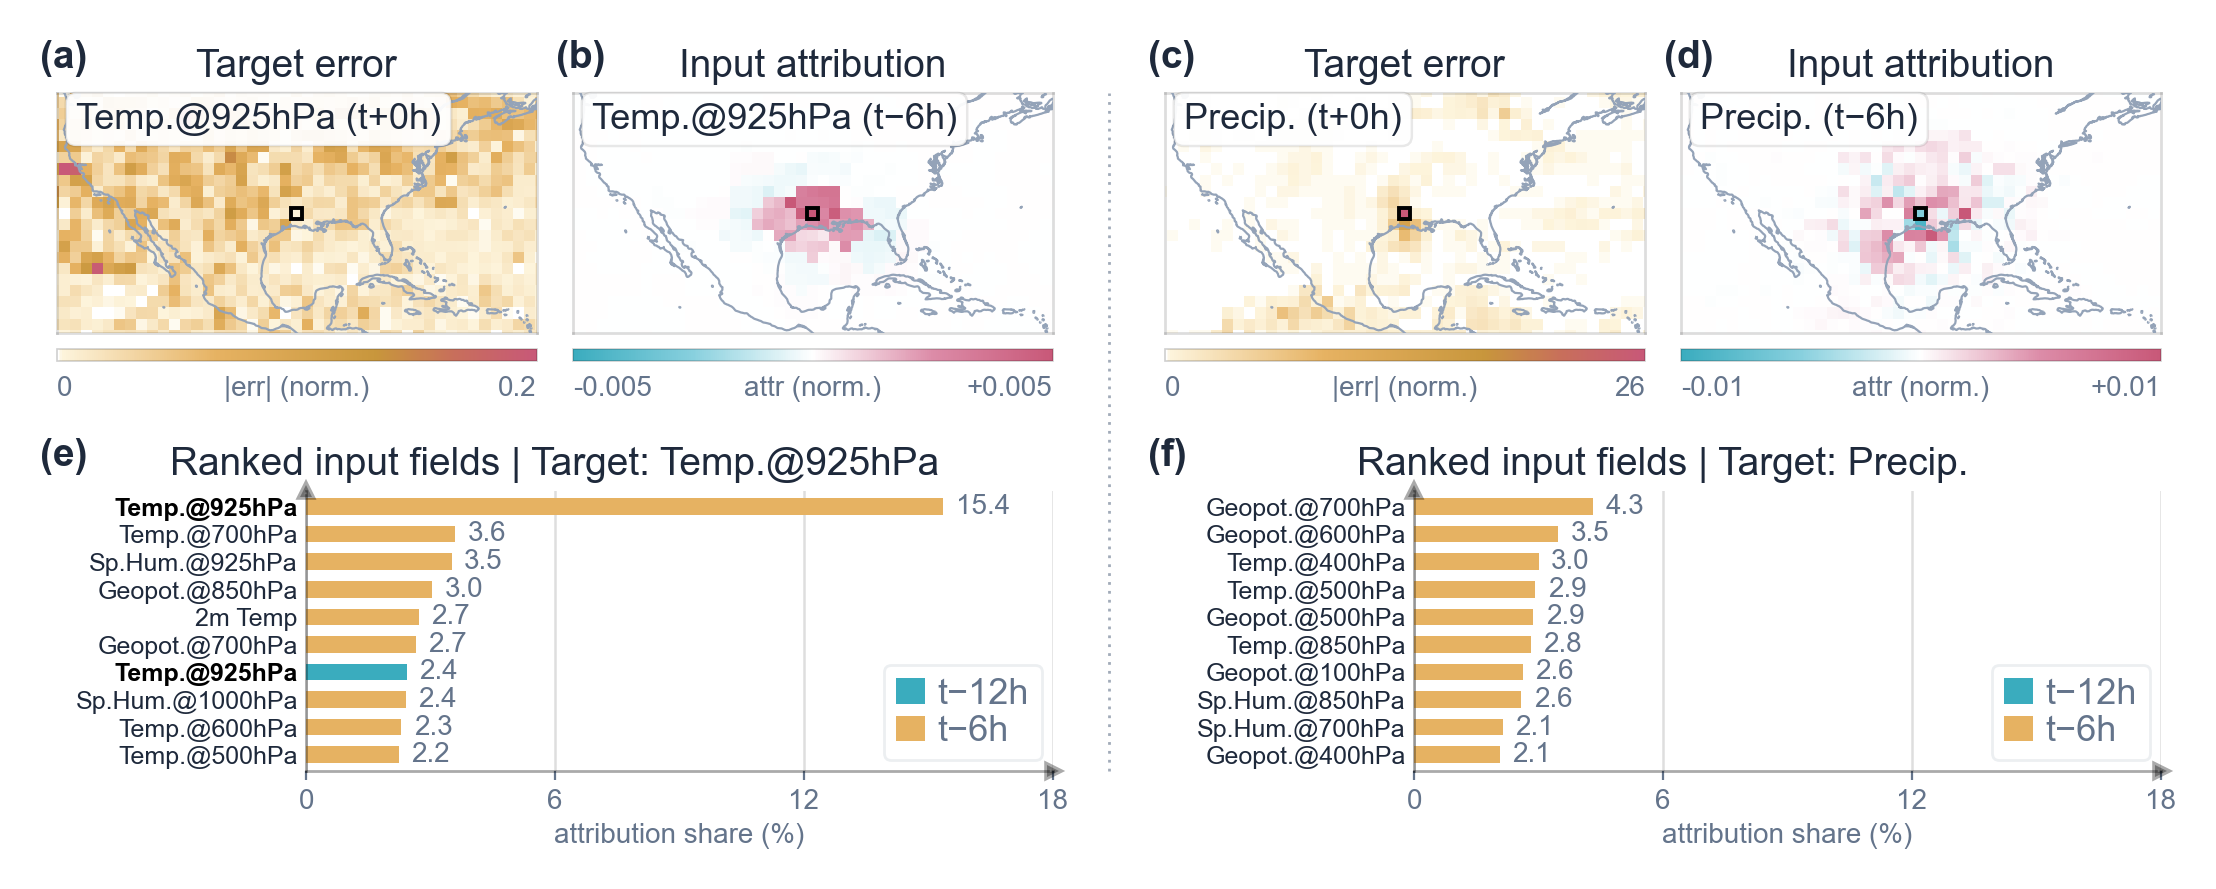

In [126]:
fig = f3.make_figure_split()
f3.save(fig, f3.fig_stem("paper_final"))

## Version A

In [26]:
f3.configure(PANEL_LETTERS=True, 
             PANEL_LETTER_SCOPE="all", 
             PANEL_LETTER_FMT="({})", 
             PANEL_LETTER_START="a",
             PANEL_LETTER_PAD=(-3, 0))  # nudge the letters left to clear the y-axis title

f3.configure(LEGEND_FS=6.5,CHIP_FS=6.5)

saved figure3_paper_temp925-precip_20200827T1200_31.5N93.0W.pdf + .png — canvas 5.51 x 3.08 in, file 5.49 x 2.89 in


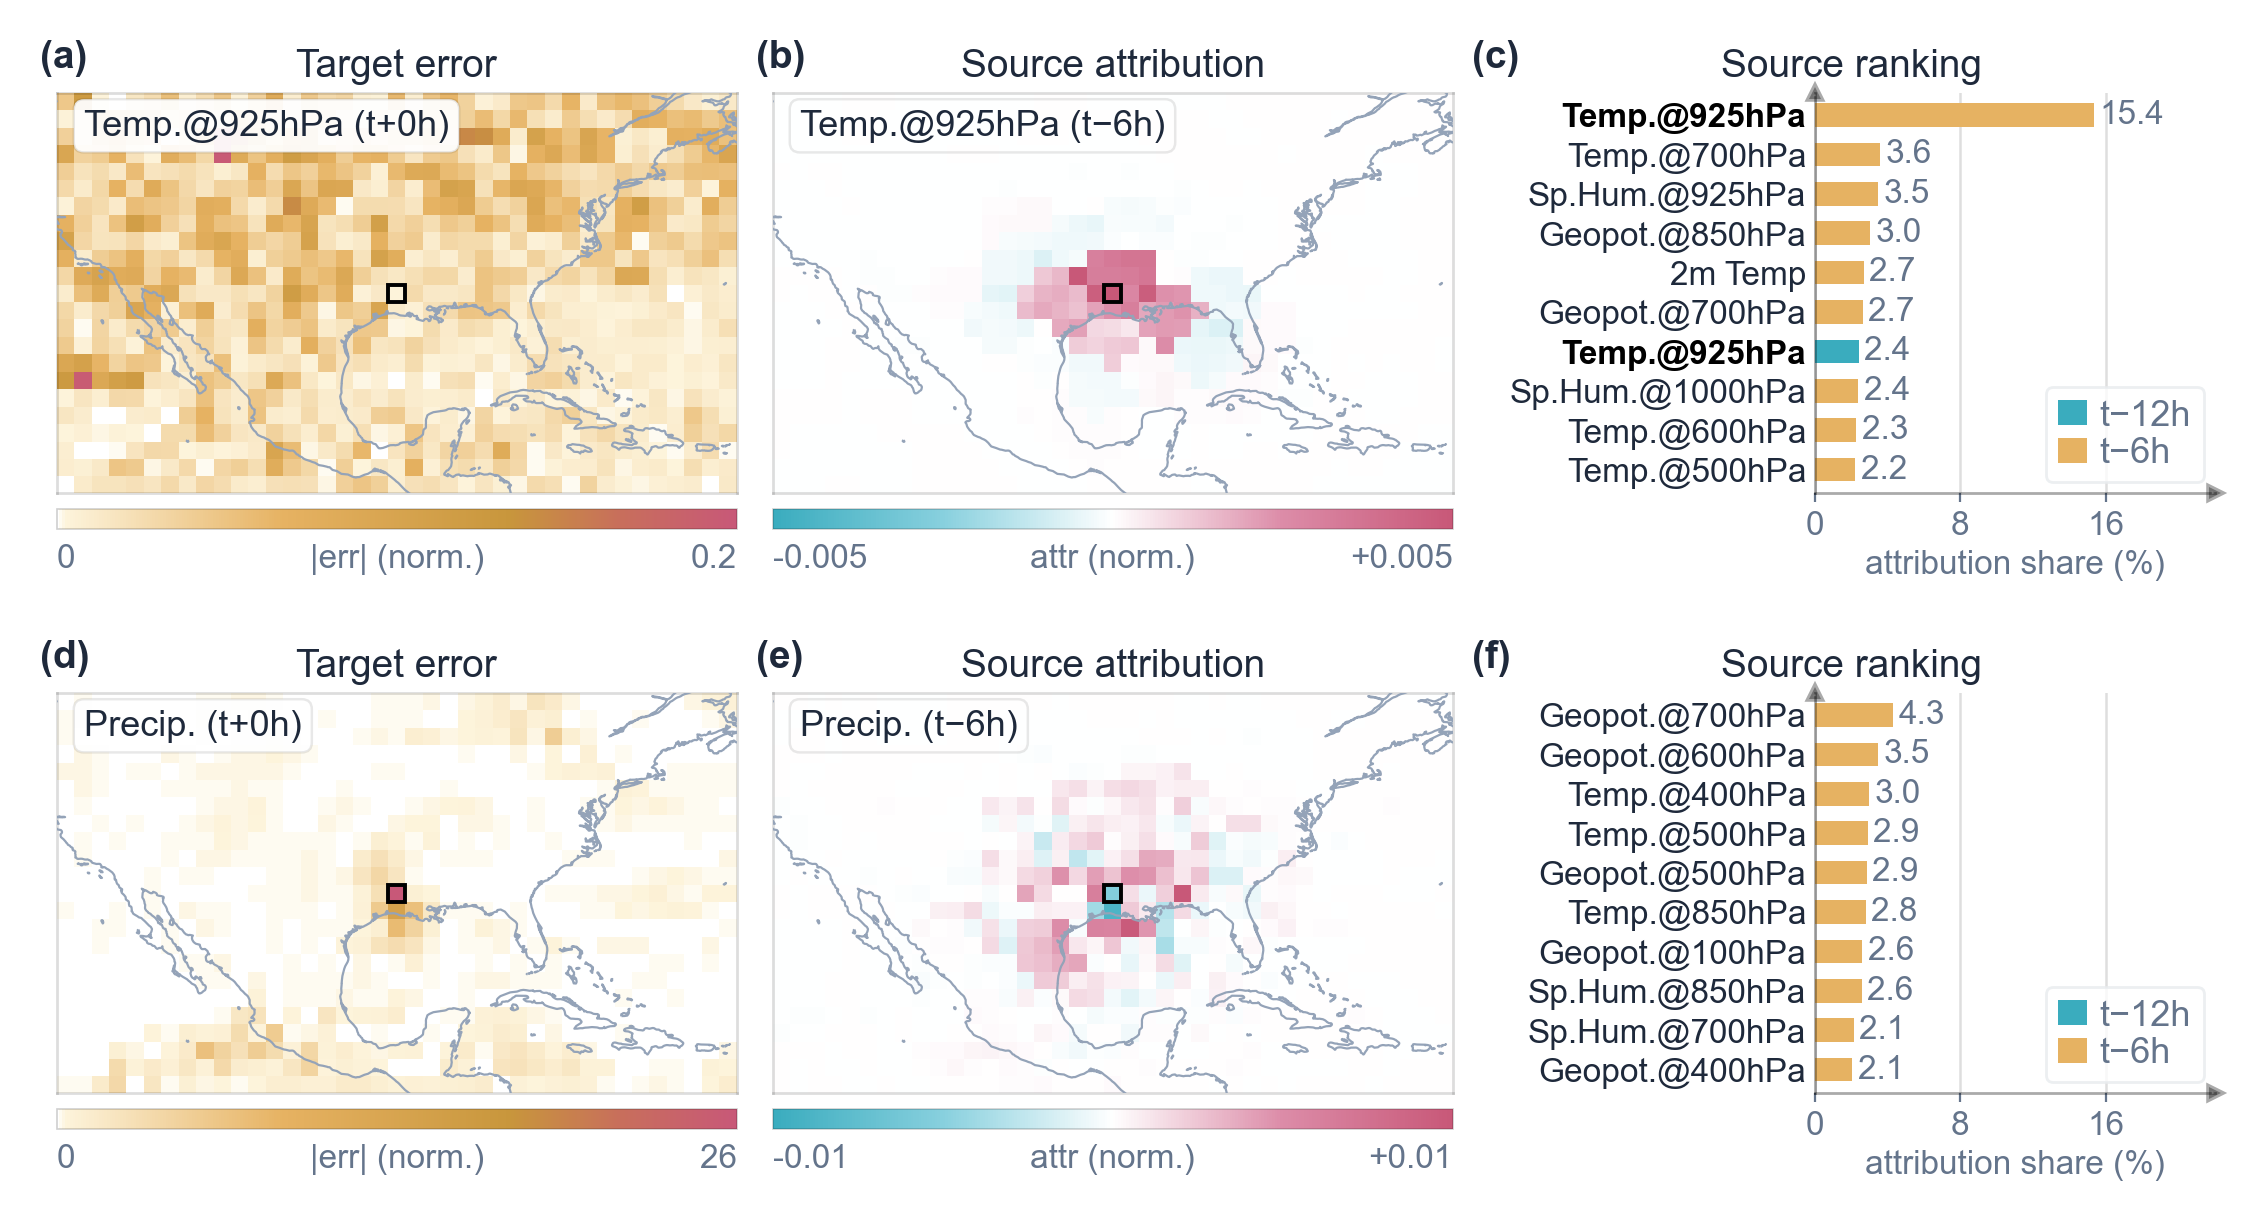

In [27]:
fig = f3.make_figure()
f3.save(fig, f3.fig_stem("paper"))
plt.show()

## Version split

In [230]:
f3.configure(PANEL_LETTERS=True, 
             PANEL_LETTER_SCOPE="all", 
             PANEL_LETTER_FMT="({})", 
             PANEL_LETTER_START="a",
             PANEL_LETTER_PAD=(-3, 0))  # nudge the letters left to clear the y-axis title

saved figure3_split_temp925-precip_20200827T1200_31.5N93.0W.pdf + .png — canvas 5.65 x 3.14 in, file 5.54 x 2.72 in


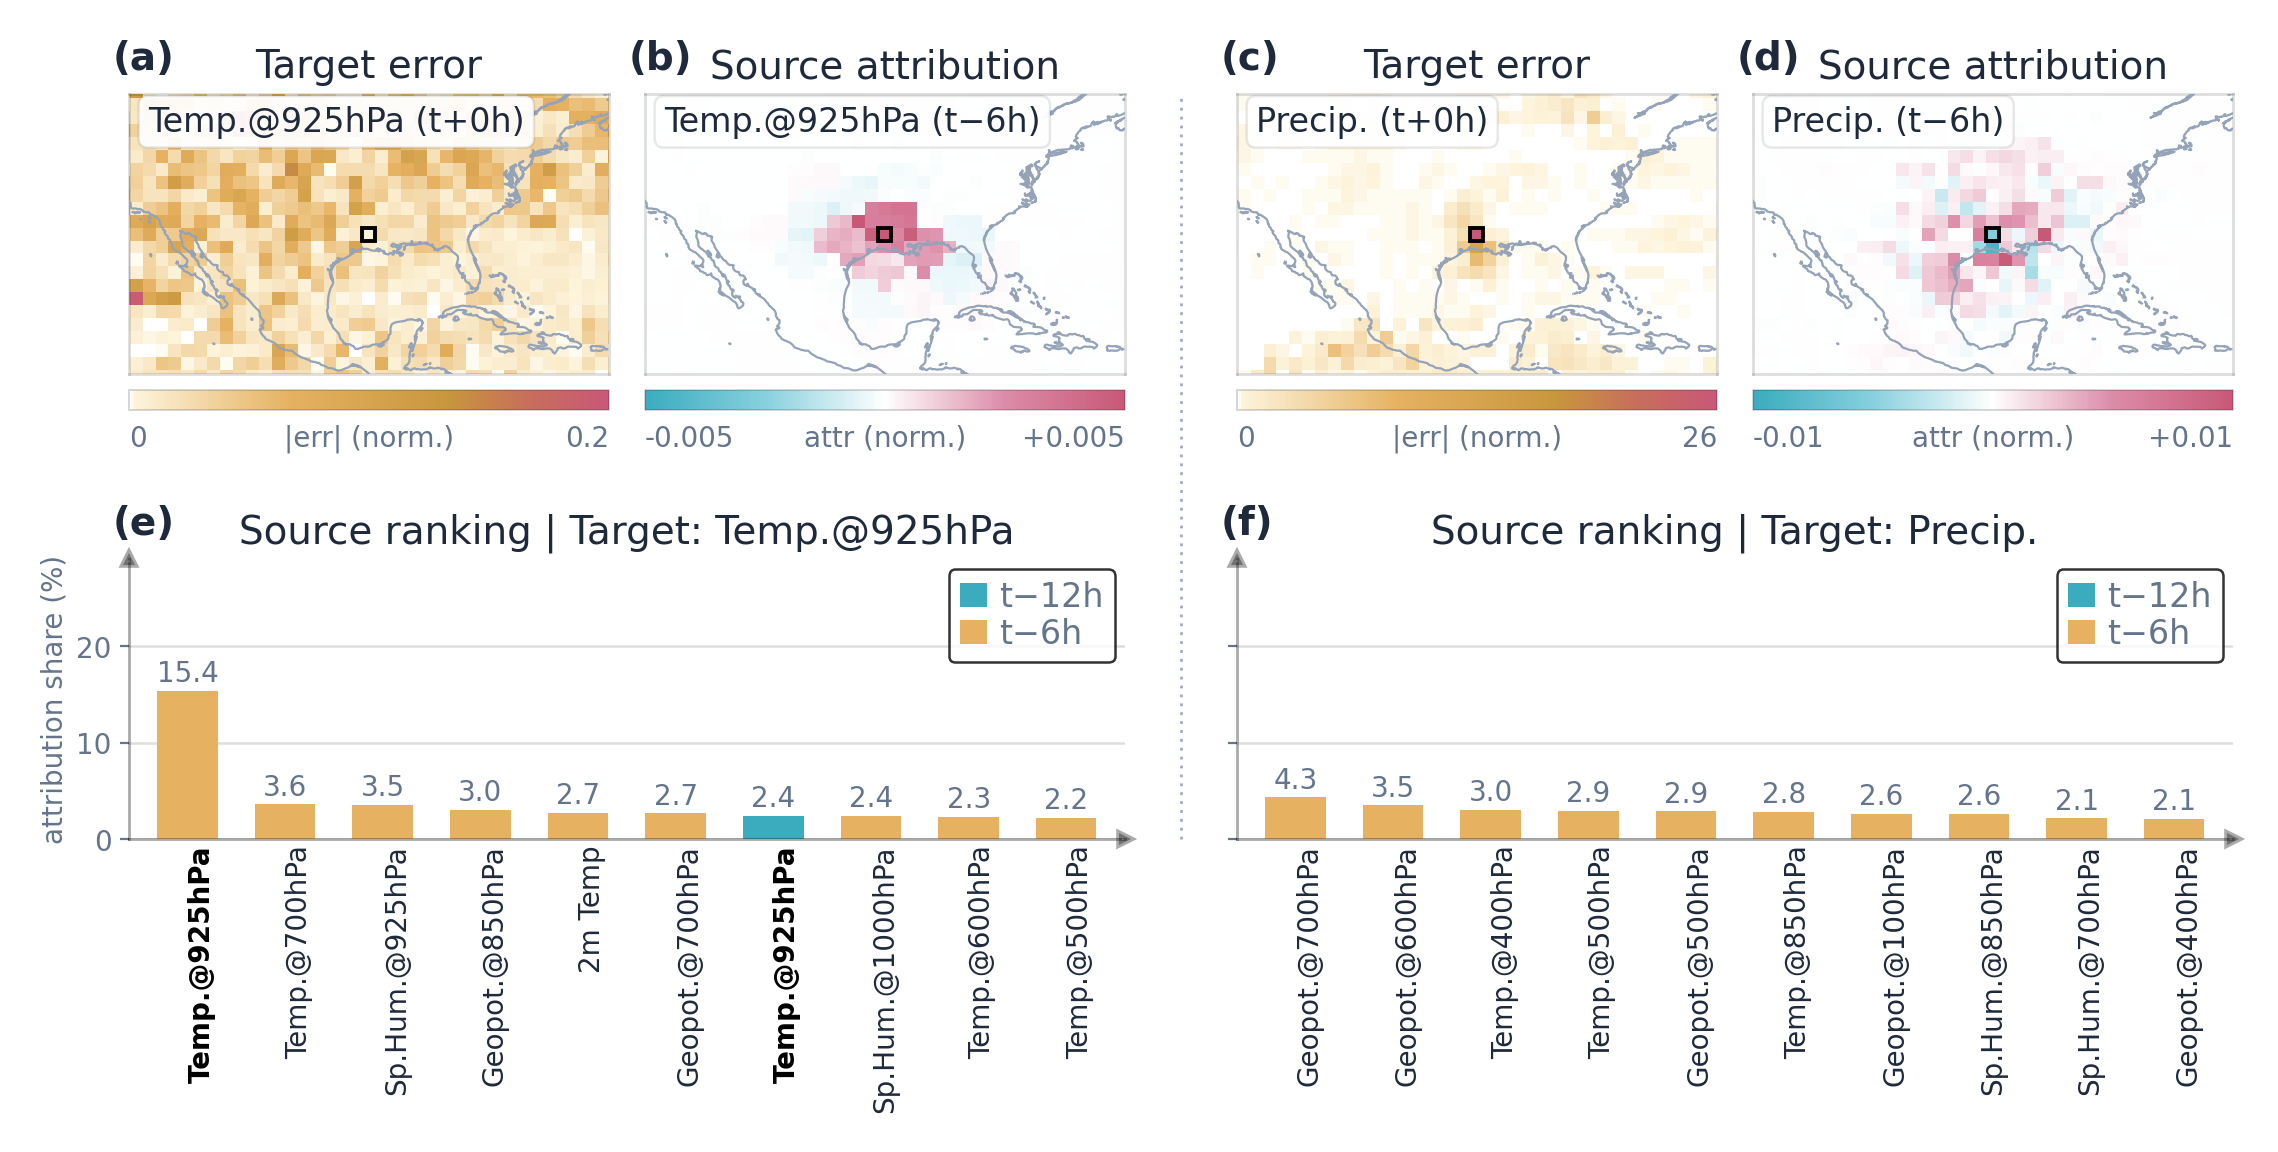

In [231]:
fig = f3.make_figure_split()
f3.save(fig, f3.fig_stem("split"))
plt.show()

## Test cases

Three alternative selections, rendered but **not saved** — uncomment the `f3.save(...)`
line under a case to write it out. Each case re-uses whatever the previous ones already
computed, so only a new (target, node) pair costs an IG run.

Note that `f3.configure` is cumulative: re-run the configuration cell above to get back
to the defaults.

In [ ]:
# 1 · 27 Aug 18:00, node (33, -93) — temperature and precipitation
f3.configure(PRED_TIME="2020-08-27T18:00:00",
             NODE_LATLON=(33.0, -93.0),
             ROWS=[dict(target=("temperature", 925),              source=("temperature", 925)),
                   dict(target=("total_precipitation_6hr", None), source=("total_precipitation_6hr", None))])
fig = f3.make_figure_split()
# f3.save(fig, f3.fig_stem("split"))
plt.show()

# 2 · same, with vertical velocity in place of precipitation
f3.configure(ROWS=[dict(target=("temperature", 925),       source=("temperature", 925)),
                   dict(target=("vertical_velocity", 925), source=("vertical_velocity", 925))])
fig = f3.make_figure_split()
# f3.save(fig, f3.fig_stem("split"))
plt.show()

# 3 · one target, two nodes: the same field and timestep attributed at (33, -93) and at
#     (31.5, -93). Each row carries its own node, so the target outline, the attribution
#     and the crop all follow it.
f3.configure(ROWS=[dict(target=("temperature", 925), source=("temperature", 925), node=(33.0, -93.0)),
                   dict(target=("temperature", 925), source=("temperature", 925), node=(31.5, -93.0))])
fig = f3.make_figure_split()
# f3.save(fig, f3.fig_stem("split"))
plt.show()